# EMQA_L7_events_hour

**Spikes come in the evening, negative prices at midday**

Energy Markets Quantitative Analysis (EMQA), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L7/EMQA_L7_events_hour/EMQA_L7_events_hour.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Share of test days with a price spike (price above the 90th percentile of the hourly prices of the 12 months before the delivery month) and with a price <= 0, by hour of the day (CET), Romanian day-ahead market, test year 2025-11-01 to 2026-10-31. Data: test year 2025-11-01 to 2026-10-31. Source: energy-charts.info (Fraunhofer ISE): OPCOM prices.

The numbers printed at the end are those on the slide of Lecture 7.

## Setup: chart style and helpers

In [2]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area (save_chart moves it just below the lowest axis label)."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=ncol, frameon=False, handlelength=1.6, handletextpad=0.5,
                   columnspacing=1.0, borderaxespad=0.1)


def save_chart(fig, name, bottom=None):
    """The axes use the whole figure height; the legend (if any) goes just below the lowest axis label."""
    fig.tight_layout(pad=0.3)
    if fig.legends:
        fig.canvas.draw()
        r = fig.canvas.get_renderer()
        y0 = min(ax.get_tightbbox(r).y0 for ax in fig.axes) / fig.bbox.height
        fig.legends[0].set_loc("upper center")
        fig.legends[0].set_bbox_to_anchor((0.5, y0 - 0.01), transform=fig.transFigure)
    plt.savefig(name + ".png", dpi=150, bbox_inches="tight", pad_inches=0.03, transparent=True)
    plt.show()


def show(label, value, fmt=""):
    """Print a number that appears on the slide."""
    print(f"{label}: {format(value, fmt)}")

## Data: Romanian day-ahead prices, CET delivery day x 24 hours

In [3]:
TZ = "Europe/Brussels"


def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


# Romanian day-ahead price (OPCOM PZU), hourly; after 1 Oct 2025 the hour is the mean of its four quarter-hours
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", usecols=["timestamp_utc", "RO"], index_col=0)
PM_ALL, DST = day_matrix(HP["RO"].dropna())          # all CET delivery days since 2015 x 24 hours
# sample of the lecture: 2022-01-01 to the cut-off 2026-10-31 (last complete month at the download of 2026-11-04)
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-10-31")
CAL = pd.date_range(START, END, freq="D")
PM = PM_ALL.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
FIRST = 7                                             # first usable target row (needs the price of d-7)
TEST0 = END - pd.Timedelta(days=364)                  # test year = the last 365 days (as in Lecture 2)
VAL0 = TEST0 - pd.Timedelta(days=365)                 # validation year = the 365 days before it
TDAYS = pd.date_range(TEST0, END, freq="D")
VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq="D")
rows_all = np.array([IDX[t] for t in TDAYS])
A = P_[rows_all]                                      # actual prices of the test year (365 days x 24 hours), EUR/MWh
print("panel", CAL[0].date(), "to", CAL[-1].date(), "| test year", TEST0.date(), "to", END.date(), A.shape)

panel 2022-01-01 to 2026-10-31 | test year 2025-11-01 to 2026-10-31 (365, 24)


## Spike threshold and events by hour

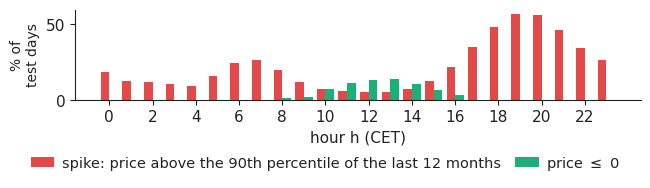

In [4]:
THR_Q = 0.90


def spike_threshold(t):
    """Spike threshold for delivery days of the month starting at t: 90th percentile of the hourly prices of the 365 days before t."""
    w = PM_ALL.loc[t - pd.Timedelta(days=365):t - pd.Timedelta(days=1)].values.ravel()
    return float(np.quantile(w, THR_Q))


_TH = {}


def theta_of(t):
    """threshold of the delivery month of day t (known at the start of the month)"""
    ms = t.replace(day=1)
    if ms not in _TH:
        _TH[ms] = spike_threshold(ms)
    return _TH[ms]


TH_T = np.array([theta_of(t) for t in TDAYS])
Y_SP = (A > TH_T[:, None]).astype(int)                # spike hours of the test year
Y_NG = (A <= 0).astype(int)                           # hours with price <= 0


h24 = np.arange(24)
fig, ax = plt.subplots(figsize=(6.4, 1.45))
ax.bar(h24 - 0.2, Y_SP.mean(0) * 100, width=0.4, color=PAL["c8"], label="spike: price above the 90th percentile of the last 12 months")
ax.bar(h24 + 0.2, Y_NG.mean(0) * 100, width=0.4, color=PAL["HU"], label="price $\\leq$ 0")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour h (CET)")
ax.set_ylabel("% of\ntest days", fontsize=10)
legend_bottom(fig, ncol=2)
save_chart(fig, "events_hour", bottom=0.26)

## Numbers on the slide

In [5]:
show('Lowest monthly threshold, EUR/MWh', TH_T.min(), '.1f')
show('Highest monthly threshold, EUR/MWh', TH_T.max(), '.1f')
show('Spike hours, % of test hours', Y_SP.mean() * 100, '.1f')
show('Spike hours', int(Y_SP.sum()), 'd')
show('Hour with most spikes', int(np.argmax(Y_SP.mean(0))), 'd')
show('Share of days with a spike at that hour, %', Y_SP.mean(0).max() * 100, '.1f')
show('Hours with price <= 0', int(Y_NG.sum()), 'd')
show('Days with a price <= 0', int(Y_NG.any(1).sum()), 'd')
show('Hour with most prices <= 0', int(np.argmax(Y_NG.mean(0))), 'd')

Lowest monthly threshold, EUR/MWh: 166.8
Highest monthly threshold, EUR/MWh: 202.4
Spike hours, % of test hours: 22.1
Spike hours: 1938
Hour with most spikes: 19
Share of days with a spike at that hour, %: 57.0
Hours with price <= 0: 255
Days with a price <= 0: 53
Hour with most prices <= 0: 13
